In [1]:
# Основные библиотеки

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Фиксируем random_state, чтобы у всех студентов получилось
# одинаковое разделение данных и результаты можно было сравнивать.
RANDOM_STATE = 42

In [2]:
def evaluate_binary(y_true, y_pred, title="Модель"):
    print(title)
    print("-" * len(title))

    print(f"Accuracy : {accuracy_score(y_true, y_pred):.3f}")
    print(f"Precision: {precision_score(y_true, y_pred):.3f}")
    print(f"Recall   : {recall_score(y_true, y_pred):.3f}")
    print(f"F1-score : {f1_score(y_true, y_pred):.3f}")

    print("\nПодробный отчет:")
    print(classification_report(y_true, y_pred, digits=3))

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        cmap="Blues"
    )
    plt.title(title)
    plt.show()

In [3]:
hearing = pd.read_csv("hearing_test.csv")

print("Размер датасета:", hearing.shape)
hearing.head()

Размер датасета: (5000, 3)


,age,physical_score,test_result
0,33.0,40.7,1
1,50.0,37.2,1
2,52.0,24.7,0
3,56.0,31.0,0
4,35.0,42.9,1


In [4]:
hearing.info()

print("\nПропущенные значения:")
print(hearing.isna().sum())

print("\nКоличество объектов каждого класса:")
print(hearing["test_result"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             5000 non-null   float64
 1   physical_score  5000 non-null   float64
 2   test_result     5000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 117.3 KB

Пропущенные значения:
age               0
physical_score    0
test_result       0
dtype: int64

Количество объектов каждого класса:
test_result
1    3000
0    2000
Name: count, dtype: int64


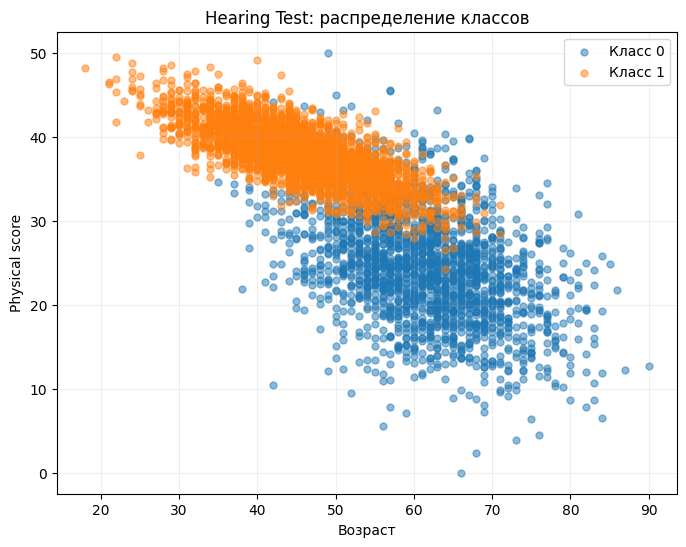

In [5]:
plt.figure(figsize=(8, 6))

for class_value, label in [(0, "Класс 0"), (1, "Класс 1")]:
    part = hearing[hearing["test_result"] == class_value]
    plt.scatter(
        part["age"],
        part["physical_score"],
        label=label,
        alpha=0.5,
        s=25
    )

plt.xlabel("Возраст")
plt.ylabel("Physical score")
plt.title("Hearing Test: распределение классов")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [6]:
X = hearing[["age", "physical_score"]]
y = hearing["test_result"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (4000, 2)
Тестовая выборка: (1000, 2)


In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

k-NN, k = 5
-----------
Accuracy : 0.927
Precision: 0.923
Recall   : 0.958
F1-score : 0.940

Подробный отчет:
              precision    recall  f1-score   support

           0      0.934     0.880     0.906       400
           1      0.923     0.958     0.940       600

    accuracy                          0.927      1000
   macro avg      0.928     0.919     0.923      1000
weighted avg      0.927     0.927     0.927      1000



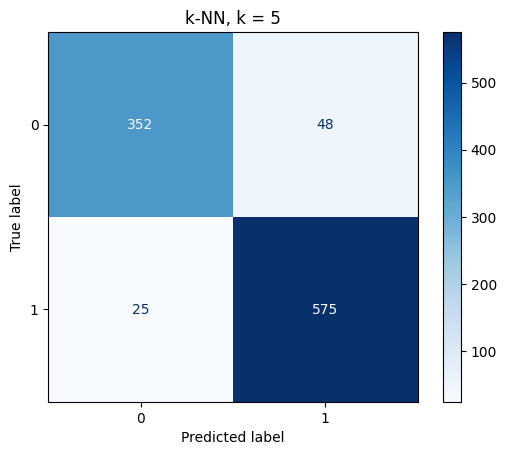

In [13]:
from sklearn.neighbors import KNeighborsClassifier

# Создаем модель: учитываем 5 ближайших соседей.
knn = KNeighborsClassifier(n_neighbors=5)

# Обучаем модель на стандартизированных данных.
knn.fit(X_train_scaled, y_train)

# Получаем прогноз для объектов, которых модель не видела при обучении.
y_pred_knn = knn.predict(X_test_scaled)

# Считаем все основные метрики.
evaluate_binary(y_test, y_pred_knn, "k-NN, k = 5")

Логистическая регрессия
-----------------------
Accuracy : 0.931
Precision: 0.922
Recall   : 0.967
F1-score : 0.944

Подробный отчет:
              precision    recall  f1-score   support

           0      0.946     0.877     0.911       400
           1      0.922     0.967     0.944       600

    accuracy                          0.931      1000
   macro avg      0.934     0.922     0.927      1000
weighted avg      0.932     0.931     0.931      1000



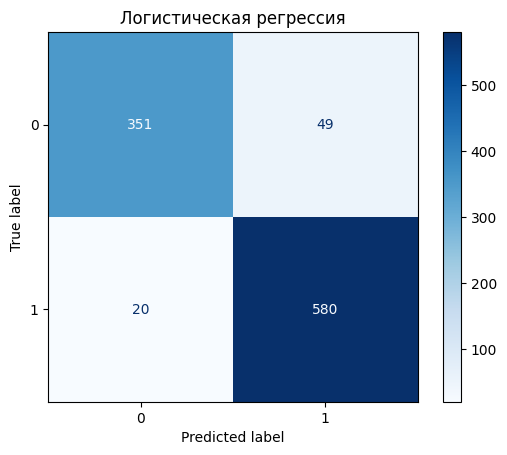

In [14]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

# Обучаем модель.
log_reg.fit(X_train_scaled, y_train)

# Предсказываем классы тестовой выборки.
y_pred_log = log_reg.predict(X_test_scaled)

# Оцениваем результат.
evaluate_binary(y_test, y_pred_log, "Логистическая регрессия")

In [17]:
probabilities = log_reg.predict_proba(X_test_scaled[:10])

result = pd.DataFrame(
    probabilities,
    columns=["P(class=0)", "P(class=1)"]
)

result["prediction"] = log_reg.predict(X_test_scaled[:10])
result["real_class"] = y_test.iloc[:10].values

result

,P(class=0),P(class=1),prediction,real_class
0,0.161110,0.838890,1,1
1,0.710498,0.289502,0,0
2,0.973485,0.026515,0,0
3,0.007512,0.992488,1,1
4,0.978032,0.021968,0,0
5,0.001332,0.998668,1,1
6,0.011931,0.988069,1,1
7,0.012746,0.987254,1,1
8,0.053770,0.946230,1,1
9,0.074726,0.925274,1,1


Дерево решений, max_depth = 4
-----------------------------
Accuracy : 0.929
Precision: 0.908
Recall   : 0.982
F1-score : 0.943

Подробный отчет:
              precision    recall  f1-score   support

           0      0.969     0.850     0.905       400
           1      0.908     0.982     0.943       600

    accuracy                          0.929      1000
   macro avg      0.938     0.916     0.924      1000
weighted avg      0.932     0.929     0.928      1000



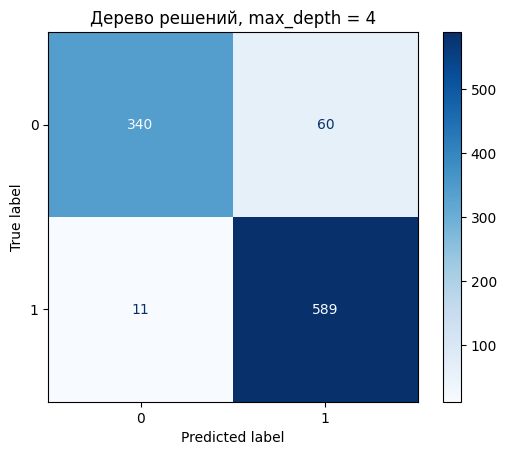

In [18]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(
    max_depth=4,
    random_state=RANDOM_STATE
)

# Для дерева используем исходные, НЕ стандартизированные признаки.
tree.fit(X_train, y_train)

y_pred_tree = tree.predict(X_test)

evaluate_binary(y_test, y_pred_tree, "Дерево решений, max_depth = 4")

Дерево решений, max_depth = 4
-----------------------------
Accuracy : 0.929
Precision: 0.908
Recall   : 0.982
F1-score : 0.943

Подробный отчет:
              precision    recall  f1-score   support

           0      0.969     0.850     0.905       400
           1      0.908     0.982     0.943       600

    accuracy                          0.929      1000
   macro avg      0.938     0.916     0.924      1000
weighted avg      0.932     0.929     0.928      1000



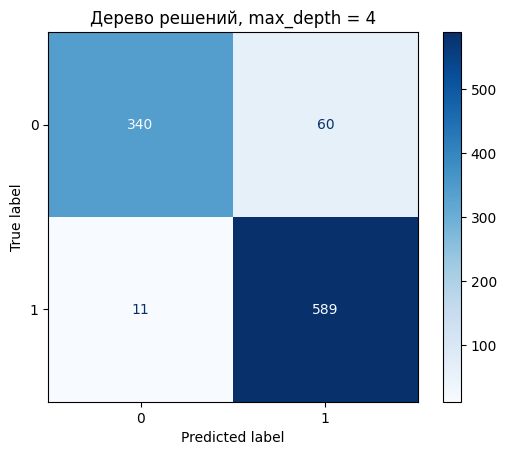

In [22]:
tree = DecisionTreeClassifier(
    max_depth=4,
    random_state=RANDOM_STATE
)

# Для дерева используем исходные, НЕ стандартизированные признаки.
tree.fit(X_train, y_train)

y_pred_tree = tree.predict(X_test)

evaluate_binary(y_test, y_pred_tree, "Дерево решений, max_depth = 4")

In [23]:
feature_importance_tree = pd.Series(
    tree.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

feature_importance_tree

,0
physical_score,0.952156
age,0.047844


Random Forest
-------------
Accuracy : 0.931
Precision: 0.915
Recall   : 0.975
F1-score : 0.944

Подробный отчет:
              precision    recall  f1-score   support

           0      0.958     0.865     0.909       400
           1      0.915     0.975     0.944       600

    accuracy                          0.931      1000
   macro avg      0.937     0.920     0.927      1000
weighted avg      0.933     0.931     0.930      1000



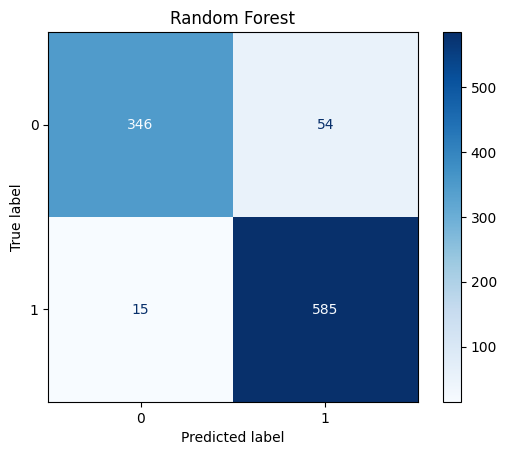

In [24]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)

evaluate_binary(y_test, y_pred_rf, "Random Forest")

In [25]:
feature_importance_rf = pd.Series(
    random_forest.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

feature_importance_rf

,0
physical_score,0.664121
age,0.335879


Gaussian Naive Bayes
--------------------
Accuracy : 0.934
Precision: 0.939
Recall   : 0.952
F1-score : 0.945

Подробный отчет:
              precision    recall  f1-score   support

           0      0.926     0.907     0.917       400
           1      0.939     0.952     0.945       600

    accuracy                          0.934      1000
   macro avg      0.933     0.930     0.931      1000
weighted avg      0.934     0.934     0.934      1000



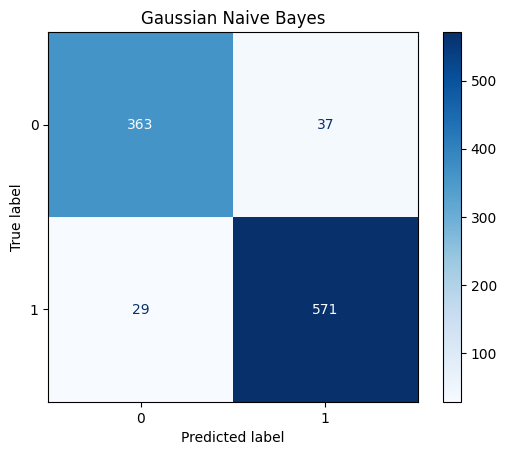

In [26]:
from sklearn.naive_bayes import GaussianNB

gaussian_nb = GaussianNB()

gaussian_nb.fit(X_train, y_train)

y_pred_gnb = gaussian_nb.predict(X_test)

evaluate_binary(y_test, y_pred_gnb, "Gaussian Naive Bayes")

In [27]:
hearing_predictions = {
    "k-NN": y_pred_knn,
    "Logistic Regression": y_pred_log,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_rf,
    "Gaussian Naive Bayes": y_pred_gnb
}

rows = []

for model_name, prediction in hearing_predictions.items():
    rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction),
        "Recall": recall_score(y_test, prediction),
        "F1": f1_score(y_test, prediction)
    })

hearing_results = pd.DataFrame(rows).sort_values(
    "F1",
    ascending=False
)

hearing_results.round(3)

,Model,Accuracy,Precision,Recall,F1
4,Gaussian Naive Bayes,0.934,0.939,0.952,0.945
3,Random Forest,0.931,0.915,0.975,0.944
1,Logistic Regression,0.931,0.922,0.967,0.944
2,Decision Tree,0.929,0.908,0.982,0.943
0,k-NN,0.927,0.923,0.958,0.940


In [30]:
tweets = pd.read_csv("airline_tweets.csv")

print("Размер датасета:", tweets.shape)

# Для нашей задачи нужны только текст сообщения и его класс.
tweets[["text", "airline_sentiment"]].head()

#tweets.head()

Размер датасета: (14640, 15)


,text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative


In [31]:
print(tweets["airline_sentiment"].value_counts())

print("\nДоли классов:")
print(
    tweets["airline_sentiment"]
    .value_counts(normalize=True)
    .round(3)
)

airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

Доли классов:
airline_sentiment
negative    0.627
neutral     0.212
positive    0.161
Name: proportion, dtype: float64


In [32]:
from sklearn.feature_extraction.text import TfidfVectorizer

# X — тексты, y — эмоциональная окраска.
X_text = tweets["text"]
y_text = tweets["airline_sentiment"]

X_text_train, X_text_test, y_text_train, y_text_test = train_test_split(
    X_text,
    y_text,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_text
)

tfidf = TfidfVectorizer(
    stop_words="english",
    min_df=2
)

# Словарь строим ТОЛЬКО по обучающим текстам.
X_tfidf_train = tfidf.fit_transform(X_text_train)

# Тестовые тексты преобразуем уже с помощью готового словаря.
X_tfidf_test = tfidf.transform(X_text_test)

print("Размер TF-IDF train:", X_tfidf_train.shape)
print("Размер TF-IDF test :", X_tfidf_test.shape)

Размер TF-IDF train: (11712, 5364)
Размер TF-IDF test : (2928, 5364)


In [33]:
def evaluate_multiclass(y_true, y_pred, title="Модель"):
    print(title)
    print("-" * len(title))

    print(f"Accuracy        : {accuracy_score(y_true, y_pred):.3f}")
    print(f"Precision macro : {precision_score(y_true, y_pred, average='macro'):.3f}")
    print(f"Recall macro    : {recall_score(y_true, y_pred, average='macro'):.3f}")
    print(f"F1 macro        : {f1_score(y_true, y_pred, average='macro'):.3f}")

    print("\nПодробный отчет:")
    print(classification_report(y_true, y_pred, digits=3))

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        cmap="Blues",
        xticks_rotation=30
    )
    plt.title(title)
    plt.show()

Логистическая регрессия + TF-IDF
--------------------------------
Accuracy        : 0.782
Precision macro : 0.756
Recall macro    : 0.666
F1 macro        : 0.699

Подробный отчет:
              precision    recall  f1-score   support

    negative      0.807     0.935     0.866      1835
     neutral      0.642     0.482     0.551       620
    positive      0.818     0.581     0.680       473

    accuracy                          0.782      2928
   macro avg      0.756     0.666     0.699      2928
weighted avg      0.774     0.782     0.769      2928



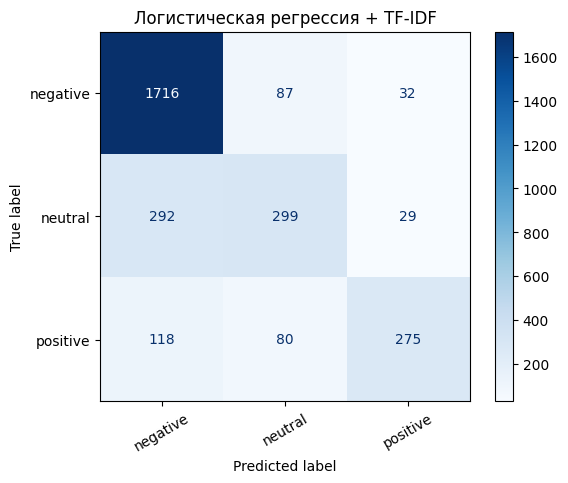

In [34]:
from sklearn.linear_model import LogisticRegression

text_log_reg = LogisticRegression(
    max_iter=1500,
    random_state=RANDOM_STATE
)

text_log_reg.fit(X_tfidf_train, y_text_train)

y_text_pred_log = text_log_reg.predict(X_tfidf_test)

evaluate_multiclass(
    y_text_test,
    y_text_pred_log,
    "Логистическая регрессия + TF-IDF"
)

Multinomial Naive Bayes + TF-IDF
--------------------------------
Accuracy        : 0.720
Precision macro : 0.765
Recall macro    : 0.513
F1 macro        : 0.547

Подробный отчет:
              precision    recall  f1-score   support

    negative      0.710     0.988     0.826      1835
     neutral      0.736     0.239     0.361       620
    positive      0.850     0.311     0.455       473

    accuracy                          0.720      2928
   macro avg      0.765     0.513     0.547      2928
weighted avg      0.738     0.720     0.668      2928



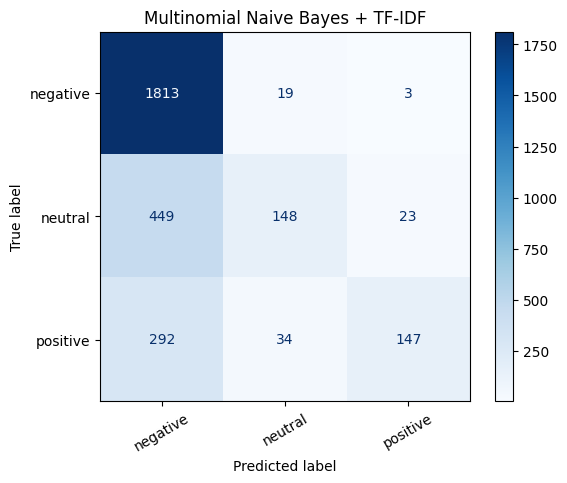

In [35]:
from sklearn.naive_bayes import MultinomialNB

text_nb = MultinomialNB()

text_nb.fit(X_tfidf_train, y_text_train)

y_text_pred_nb = text_nb.predict(X_tfidf_test)

evaluate_multiclass(
    y_text_test,
    y_text_pred_nb,
    "Multinomial Naive Bayes + TF-IDF"
)